Dataset shape: (4998, 140)
Epoch 1/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.2956 - val_loss: 0.0547
Epoch 2/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0408 - val_loss: 0.0305
Epoch 3/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0264 - val_loss: 0.0223
Epoch 4/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0199 - val_loss: 0.0170
Epoch 5/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0154 - val_loss: 0.0133
Epoch 6/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0126 - val_loss: 0.0112
Epoch 7/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0110 - val_loss: 0.0102
Epoch 8/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0100 - val_loss: 0.0092
Epoch 9/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0092 - val_loss: 0.0086
Epoch 10/10
73/73 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0086 - val_loss: 0.0081
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Anomaly threshold: 0.01722473792782674
Acc

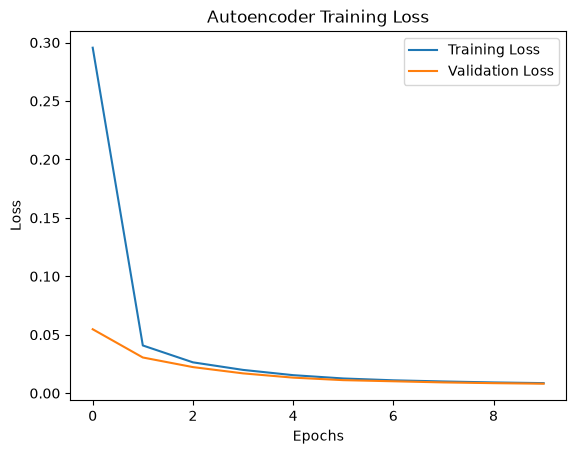

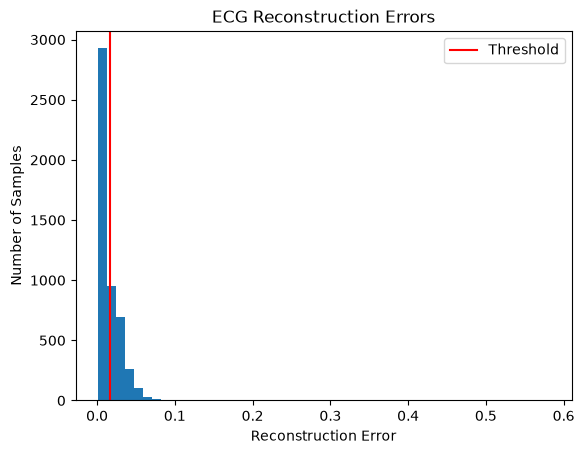

Model saved successfully!


In [1]:

# STEP 1: Import libraries

import pandas as pd
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# STEP 2: Load ECG dataset

data = pd.read_csv("ecg.csv", header=None)

# Separate ECG signals and labels
X = data.iloc[:, :-1].values
y = data.iloc[:, -1].values

print("Dataset shape:", X.shape)

# STEP 3: Select only normal ECG signals

normal_label = 1

X_normal = X[y == normal_label]

# Normalize the data
mean = X_normal.mean()
std = X_normal.std()

X_normal = (X_normal - mean) / std
X_all = (X - mean) / std

# Reshape for Conv1D
X_normal = X_normal.reshape(X_normal.shape[0], X_normal.shape[1], 1)
X_all = X_all.reshape(X_all.shape[0], X_all.shape[1], 1)

# Split normal data into training and validation
X_train = X_normal[:int(0.8 * len(X_normal))]
X_val = X_normal[int(0.8 * len(X_normal)):]

# STEP 4: Build 1D Convolutional Autoencoder

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(X_train.shape[1], 1)),

    # Encoder
    tf.keras.layers.Conv1D(32, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling1D(2, padding='same'),

    tf.keras.layers.Conv1D(16, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling1D(2, padding='same'),

    # Decoder
    tf.keras.layers.Conv1D(16, 3, activation='relu', padding='same'),
    tf.keras.layers.UpSampling1D(2),

    tf.keras.layers.Conv1D(32, 3, activation='relu', padding='same'),
    tf.keras.layers.UpSampling1D(2),

    tf.keras.layers.Conv1D(1, 3, activation='linear', padding='same')
])

# STEP 5: Compile the model

model.compile(optimizer='adam', loss='mse')

# STEP 6: Train using normal ECG signals

history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_val, X_val)
)

# STEP 7: Calculate reconstruction error

reconstructed = model.predict(X_all)

errors = np.mean(np.square(X_all - reconstructed), axis=(1, 2))

# Set threshold using normal validation data
val_reconstructed = model.predict(X_val)

val_errors = np.mean(
    np.square(X_val - val_reconstructed), axis=(1, 2)
)

threshold = np.percentile(val_errors, 95)

print("Anomaly threshold:", threshold)

# STEP 8: Detect anomalies

predictions = (errors > threshold).astype(int)

# Actual labels: normal = 0, abnormal = 1
actual = (y != normal_label).astype(int)

accuracy = np.mean(predictions == actual) * 100

print("Accuracy:", accuracy, "%")

# STEP 9: Plot training loss

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Autoencoder Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

# STEP 10: Display anomaly detection results

plt.hist(errors, bins=50)
plt.axvline(threshold, color='red', label='Threshold')
plt.title("ECG Reconstruction Errors")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Samples")
plt.legend()
plt.show()

# STEP 11: Save model

model.save("ecg_autoencoder.keras")

print("Model saved successfully!")


## Practical 3B – Industrial Equipment Anomaly Detection using Autoencoder

Problem statement: Implement Industrial Equipment Anomaly Detection on the MVTec AD Kaggle dataset using a Convolutional Autoencoder. Train the model using defect-free images and detect defects using reconstruction errors.

Important: Your code does not match the given practical

Your practical is about industrial images (MVTec AD), but the code you shared is for ECG signals. Let's understand the difference before going through the code.

### 1. What is the difference?

| Your practical (3B)         | Your current code     |
| --------------------------- | --------------------- |
| MVTec AD image dataset      | ECG signal dataset    |
| Industrial defect detection | ECG anomaly detection |
| `Conv2D`                    | `Conv1D`              |
| `MaxPooling2D`              | `MaxPooling1D`        |
| `UpSampling2D`              | `UpSampling1D`        |
| Image reconstruction        | Signal reconstruction |
| `ecg.csv`                   | CSV-based ECG data    |

Why is this important?

- `Conv1D` works with one-dimensional data, such as ECG signals.
- `Conv2D` works with two-dimensional data, such as industrial images.

Your code is logically an autoencoder anomaly-detection program, but it solves a different problem.

### 2. Understand the concept first

Imagine a factory checking metal objects for defects.

[Visual Anomaly Detection with Anomalib: A Hands-On Guide \[2026\] | Datature Blog](https://images.openai.com/static-rsc-4/LI6_JiHr83VinqiITRGDRDs_6KVGLWIBsK_PlPAxDnvmXjNYC5fOkDiZsmGAou2E5iVaCJrtiOZF1pUieLyjjRN9Fh2spOmldawM0cla4Q8p__hXtpl1apQA9ie4wiS1zSkc4BOFSkVj4o6LszHyorA9PX6JFtI0Eif2DX5o1tE?purpose=inline)

[Figure 5 - from Hierarchical Image Transformation and](https://images.openai.com/static-rsc-4/4AZjKuKS00BCsQEB04smSkYXNHIMDMkAFMaiqejZOX0OA_s_70wCTmz1Hiq-sfE8BHsPlI0Csrri4Gya2JxoNBHJSD3RoUWmII6yJWn_M2aj3O17kNM6ef4IA6ymOAVrcpyxIQrrtwtnt0S75dK_p7KDV8TFwBNkLB0FkMIRkSQ?purpose=inline)

[HALCON 19.11: MVTec Software](https://images.openai.com/static-rsc-4/jZGxtyvpe5e6e1ESp6N7veOPsJYwJx7-icDPc4yQc5op1EmN8MM-fIw0kgNz-kspjOX-lYC8UVDv-tJugBsqGPKlmjuVdIVn0CFXSgwk59AQALghuKEwmcn4QWQnDSntRH72RWrkEvBqQlnAoAJpQO88Lt5wtFMvif4t-nAeR1E?purpose=inline)

7

The model works like this:

1. Give the model only normal, defect-free images.
2. The encoder compresses the image into important features.
3. The decoder reconstructs the original image.
4. Give it a test image containing a defect.
5. The reconstruction error helps identify whether the image is abnormal.

Simple example:

- Normal image → low reconstruction error.
- Defective image → high reconstruction error.
- If error is greater than the threshold → classify it as an anomaly.

### 3. Important concepts in your code

Even though your code uses ECG data, these concepts are also used in the image-based practical.

| Code / concept                    | Simple meaning                       |
| --------------------------------- | ------------------------------------ |
| `normal_label = 1`                | Selects the normal ECG class         |
| `X_normal = X[y == normal_label]` | Keeps only normal samples            |
| Normalization                     | Scales data for easier learning      |
| Encoder                           | Compresses input data                |
| Decoder                           | Reconstructs input data              |
| `mse`                             | Measures reconstruction error        |
| `threshold`                       | Boundary between normal and abnormal |
| `predictions`                     | Final anomaly decisions              |
| `model.save()`                    | Saves the trained model              |

### 4. What needs to change for the actual MVTec AD practical?

Your image-based code needs:

- Load normal and defective images from the MVTec AD folder structure.
- Resize images, for example to `128 × 128`.
- Normalize pixel values using `/255.0`.
- Use `Conv2D` and `MaxPooling2D` in the encoder.
- Use `UpSampling2D` and `Conv2D` in the decoder.
- Train only on normal images.
- Calculate pixel reconstruction errors and compare them against a threshold.

One important thing: MVTec AD contains multiple object categories, such as bottle, cable, capsule, carpet, and metal nut. The folder structure and selected category matter when loading the images.

### 5. Viva questions

Q1. What is an Autoencoder?\
An autoencoder is a neural network that learns to compress and reconstruct input data.

Q2. Why do we train only on normal images?\
So the model learns the normal appearance and struggles to reconstruct defective images accurately.

Q3. What is the difference between Conv1D and Conv2D?\
Conv1D processes sequential data, while Conv2D processes images.

Q4. What is reconstruction error?\
It is the difference between the original input and the reconstructed output.

Q5. What is a threshold?\
It is the value used to decide whether an input is normal or anomalous.

### Before we proceed

Your current code is for ECG, not MVTec AD. I recommend using the actual MVTec AD image dataset for Practical 3B so that your code matches the examiner's problem statement.

I can provide the complete, simplified, runnable MVTec AD code using your local dataset, with clear folder-path assumptions and explanations.